# 04 - Exploratory Data Analysis

In this notebook I explore the clean data with charts before I segment the customers. I look at the sales over time, the countries and products that bring in the most revenue, when people shop, and what the Recency, Frequency and Monetary values look like. The goal is to understand the shape of the data and to find anything that could affect the clustering.

## 1. Load the data

I use two tables. `sales` holds every clean sale, including the rows without a customer, because the sales trends are about the store and not about the customers. `rfm` has one row per customer and is used for the customer charts.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

PROCESSED_DIR = "../data/processed"
sales = pd.read_csv(f"{PROCESSED_DIR}/sales_clean.csv", index_col="raw_index", parse_dates=["InvoiceDate"], dtype={"InvoiceNo": "string", "StockCode": "string", "CustomerID": "Int64"})
rfm = pd.read_csv(f"{PROCESSED_DIR}/rfm.csv", index_col="CustomerID")
print(sales.shape)
print(rfm.shape)


(522500, 8)
(4320, 3)


In [2]:
sales["Revenue"] = sales["UnitPrice"] * sales["Quantity"]
print(sales.shape)
print(sales.dtypes)
print(rfm.dtypes)

(522500, 9)
InvoiceNo              string
StockCode              string
Description               str
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID              Int64
Country                   str
Revenue               float64
dtype: object
Recency        int64
Frequency      int64
Monetary     float64
dtype: object


In [3]:
assert len(sales) == 522500, f"Expected sales row count 522500, got {len(sales)}"
assert len(rfm) == 4320, f"Expected rfm row count 4320, got {len(rfm)}"
assert (sales["Revenue"] > 0).all(), "Not all Revenue values in sales are greater than 0"
assert round(sales["Revenue"].sum(), 2) == 10000615.82, "Total Revenue in sales does not equal 10000615.82"
assert round(rfm["Monetary"].sum(), 2) == 8266432.85, "Total Monetary in rfm does not equal 8266432.85"
assert rfm.index.isin(sales["CustomerID"]).all(), "Some customers in rfm are not present in sales"

`sales` has 522,500 rows and `rfm` has 4,320 customers. The total revenue in `sales` is 10,000,615.82, and the total Monetary in `rfm` is 8,266,432.85. The Monetary total is lower because `rfm` only has customers with an ID, and it also subtracts the cancellations of real products.

## 2. Sales over time

First I look at how the revenue and the number of invoices change per month. The data ends on 9 December 2011, so the last month is incomplete, and I have to be careful when I read it.

In [4]:
sales["Month"] = sales["InvoiceDate"].dt.to_period("M")
monthly = sales.groupby("Month").agg(
    revenue=("Revenue", "sum"),
    invoices=("InvoiceNo", "nunique")
)
monthly["revenue"] = monthly["revenue"].round(2)
print(monthly)

            revenue  invoices
Month                        
2010-12   775572.23      1550
2011-01   593178.39      1080
2011-02   507783.42      1093
2011-03   689708.49      1440
2011-04   515354.78      1235
2011-05   739899.50      1668
2011-06   737558.98      1525
2011-07   688144.79      1452
2011-08   724196.76      1339
2011-09  1028313.80      1818
2011-10  1103310.96      2005
2011-11  1451575.69      2751
2011-12   446018.03       815


In [5]:
assert len(monthly) == 13, f"Expected monthly row count 13, got {len(monthly)}"
assert round(monthly["revenue"].sum(), 2) == 10000615.82, "Total monthly revenue does not equal 10000615.82"
assert monthly["invoices"].sum() == 19771, f"Expected total invoices 19771, got {monthly['invoices'].sum()}"

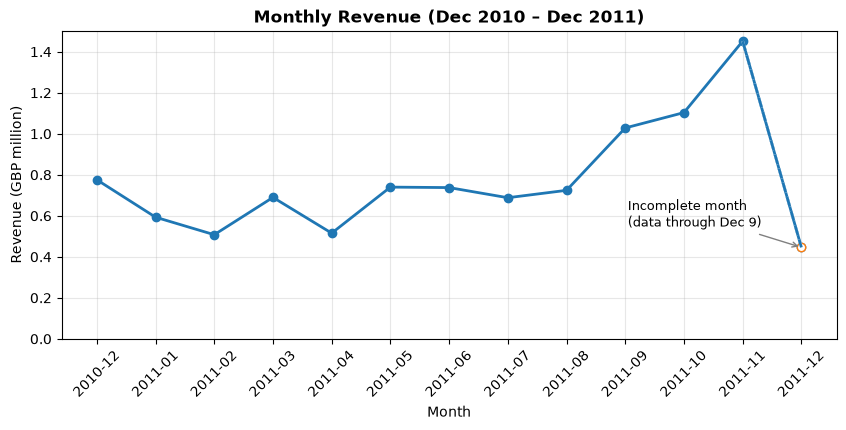

In [6]:
x_values = monthly.index.astype(str)
y_values = monthly["revenue"] / 1_000_000


fig, ax = plt.subplots(figsize=(10,4))

ax.set_title("Monthly Revenue (Dec 2010 – Dec 2011)", fontsize=12, fontweight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (GBP million)")

ax.plot(x_values, y_values, marker="o", linewidth=2)
ax.tick_params(axis="x", rotation=45)
ax.grid(True, alpha=0.3)

last_x = x_values[-1]
last_y = y_values.iloc[-1]
ax.plot(last_x, last_y, marker="o", markerfacecolor="white")

ax.annotate(
    "Incomplete month\n(data through Dec 9)",
    xy=(last_x, last_y),
    xytext=(-125, 15),
    textcoords="offset points",
    fontsize=9,
    arrowprops=dict(arrowstyle="->", color="gray", lw=1)
)

ax.set_ylim(bottom=0)
ax.plot(x_values[-2:], y_values.iloc[-2:], linestyle="--", color="white", linewidth=2)
ax.plot(x_values[-2:], y_values.iloc[-2:], linestyle="--", color="tab:blue", linewidth=2)

fig.savefig("../reports/monthly_revenue.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
sales["Date"] = sales["InvoiceDate"].dt.normalize()
active_days = sales.groupby("Month")["Date"].nunique()
monthly["active_days"] = active_days
monthly["revenue_per_day"] = (monthly["revenue"] / monthly["active_days"]).round(2)
print(monthly[["revenue", "active_days", "revenue_per_day"]])

            revenue  active_days  revenue_per_day
Month                                            
2010-12   775572.23           20         38778.61
2011-01   593178.39           24         24715.77
2011-02   507783.42           24         21157.64
2011-03   689708.49           27         25544.76
2011-04   515354.78           21         24540.70
2011-05   739899.50           25         29595.98
2011-06   737558.98           26         28367.65
2011-07   688144.79           26         26467.11
2011-08   724196.76           26         27853.72
2011-09  1028313.80           26         39550.53
2011-10  1103310.96           26         42435.04
2011-11  1451575.69           26         55829.83
2011-12   446018.03            8         55752.25


Revenue goes from 0.78 million in December 2010 to a peak of 1.45 million in November 2011, and September to November 2011 is clearly higher than the rest of the year. December 2011 is only 0.45 million because the data stops on 9 December, but it has 8 active days and about 55,752 revenue per active day, almost the same as November (55,830). So the low point is caused by the missing days, not by a drop in sales. The chart is saved in `reports/monthly_revenue.png`.

## 3. Revenue by country

The store is based in the United Kingdom, so I expect most of the revenue to come from there. I look at the top 10 countries first, and then at the top 10 without the United Kingdom, because one huge bar would hide the differences between the other countries.

In [8]:
revenue_by_country = (sales.groupby("Country")["Revenue"].sum()).sort_values(ascending=False)
country_share = (revenue_by_country / revenue_by_country.sum()) * 100
print(len(revenue_by_country))

top_countries = pd.DataFrame({
    "Revenue": revenue_by_country,
    "Share (%)": country_share
    }).head(10).round(2)
print(top_countries)

38
                   Revenue  Share (%)
Country                              
United Kingdom  8477840.17      84.77
Netherlands      283889.34       2.84
EIRE             270850.86       2.71
Germany          205381.15       2.05
France           184493.00       1.84
Australia        138103.81       1.38
Spain             55706.56       0.56
Switzerland       53065.60       0.53
Japan             37416.37       0.37
Belgium           36927.34       0.37


In [9]:
assert len(revenue_by_country) == 38, f"Expected 38 countries, got {len(revenue_by_country)}"
assert round(revenue_by_country.sum(), 2) == 10000615.82, "Total revenue_by_country does not equal 10000615.82"
assert round(country_share.sum(), 2) == 100.0, "Total country_share does not equal 100.0"

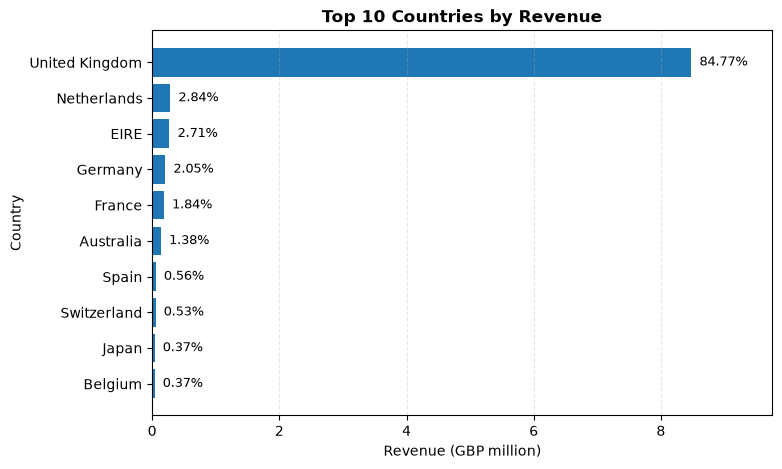

In [10]:
top_countries = revenue_by_country.head(10)
top_shares = country_share.head(10)

names = top_countries.index
values = top_countries.values / 1_000_000
share_labels = [f" {pct:.2f}%" for pct in top_shares]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(names, values)
ax.invert_yaxis()
ax.bar_label(bars, labels=share_labels, padding=3, fontsize=9)
ax.set_xlim(0, values.max() * 1.15)

ax.set_title("Top 10 Countries by Revenue", fontsize=12, fontweight="bold")
ax.set_xlabel("Revenue (GBP million)")
ax.set_ylabel("Country")
ax.grid(axis="x", linestyle="--", alpha=0.3)

fig.savefig("../reports/revenue_by_country.png", dpi=150, bbox_inches="tight")
plt.show()

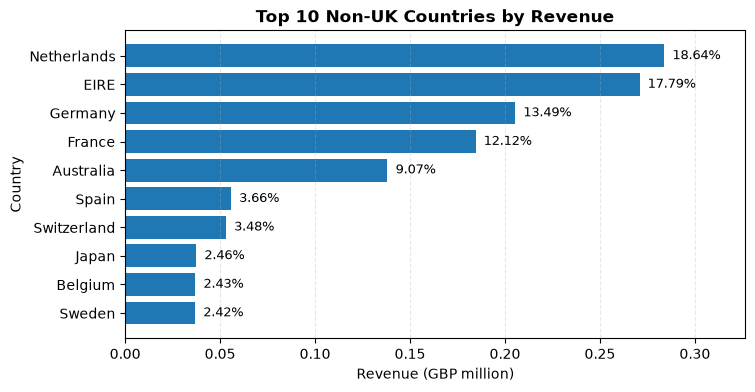

In [11]:
no_uk_revenue = revenue_by_country.drop("United Kingdom")
top_countries_no_uk = no_uk_revenue.head(10)

no_uk_shares = (top_countries_no_uk / no_uk_revenue.sum()) * 100

names = top_countries_no_uk.index
values = top_countries_no_uk.values / 1_000_000
share_labels = [f" {pct:.2f}%" for pct in no_uk_shares]

fig, ax = plt.subplots(figsize=(8,4))
bars = ax.barh(names, values)
ax.invert_yaxis()
ax.bar_label(bars, labels=share_labels, padding=3, fontsize=9)
ax.set_xlim(0, values.max() * 1.15)

ax.set_title("Top 10 Non-UK Countries by Revenue", fontsize=12, fontweight="bold")
ax.set_xlabel("Revenue (GBP million)")
ax.set_ylabel("Country")
ax.grid(axis="x", linestyle="--", alpha=0.3)

fig.savefig("../reports/revenue_by_country_no_uk.png", dpi=150, bbox_inches="tight")
plt.show()

The United Kingdom brings in 8.48 million of the 10.00 million revenue (84.77%), and the other 37 countries together make up the remaining 15.23%. Without the UK, the top countries are Netherlands, EIRE and Germany, and the top five together make up about 71.1% of the non-UK revenue. The charts are saved in `reports/`. Because the business depends so much on one market, I will check later whether the customer segments look different inside and outside the UK.

## 4. Best-selling products

Next I look at which products bring in the most money and which ones are sold the most in pieces. These can be different, because a cheap item can sell a lot of pieces and still bring in little revenue. I also check how concentrated the revenue is, meaning how many products it takes to reach half or most of the revenue.

In [12]:
products = sales.groupby("StockCode").agg(
    Description=("Description", "first"),
    revenue=("Revenue", "sum"),
    quantity=("Quantity", "sum"),
    invoices=("InvoiceNo", "nunique")
)
products.shape

(3790, 4)

In [13]:
assert len(products) == 3790, f"Expected 3790 rows in products, got {len(products)}"
assert round(products["revenue"].sum(), 2) == 10000615.82, "Total product revenue does not equal 10000615.82"
assert products["quantity"].sum() == 5405767, f"Expected total quantity 5405767, got {products['quantity'].sum()}"

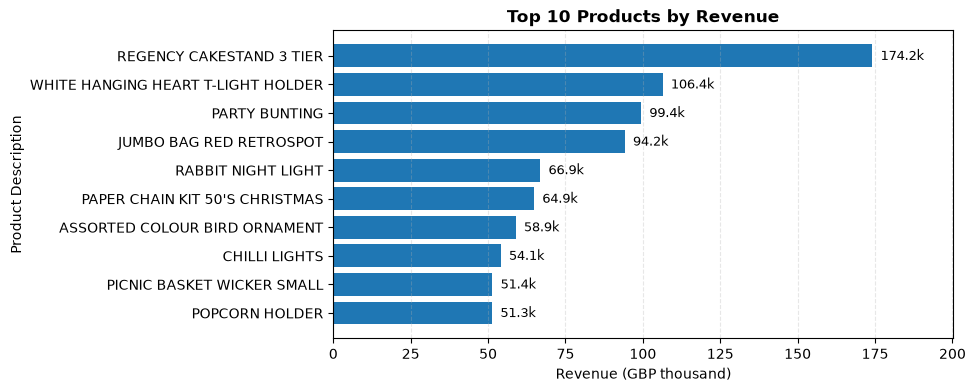

In [14]:
top_by_revenue = products.nlargest(10, "revenue")

names = top_by_revenue["Description"]
values = top_by_revenue["revenue"] / 1_000
value_labels = [f" {val:,.1f}k" for val in values]

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(names, values)
ax.invert_yaxis()
ax.bar_label(bars, labels=value_labels, padding=3, fontsize=9)
ax.set_xlim(0, values.max() * 1.15)

ax.set_title("Top 10 Products by Revenue", fontsize=12, fontweight="bold")
ax.set_xlabel("Revenue (GBP thousand)")
ax.set_ylabel("Product Description")
ax.grid(axis="x", linestyle="--", alpha=0.3)

fig.savefig("../reports/top_products_revenue.png", dpi=150, bbox_inches="tight")
plt.show()

In [15]:
top_by_quantity = products.nlargest(10, "quantity")
print("top 10 products by quantity:")
print(top_by_quantity[["Description", "quantity", "revenue"]].round({"revenue": 2}))
common_products = set(top_by_revenue.index) & set(top_by_quantity.index)
print("\nNumber of products in both top 10 lists:", len(common_products))

top 10 products by quantity:
                                  Description  quantity    revenue
StockCode                                                         
22197                          POPCORN HOLDER     56898   51334.47
84077       WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951   13814.01
85099B                JUMBO BAG RED RETROSPOT     48371   94159.81
85123A     WHITE HANGING HEART T-LIGHT HOLDER     37933  106415.23
21212         PACK OF 72 RETROSPOT CAKE CASES     36396   21246.45
84879           ASSORTED COLOUR BIRD ORNAMENT     36362   58927.62
23084                      RABBIT NIGHT LIGHT     30739   66870.03
22492                  MINI PAINT SET VINTAGE     26633   16937.82
22616               PACK OF 12 LONDON TISSUES     26119    7975.98
21977      PACK OF 60 PINK PAISLEY CAKE CASES     24820   12226.32

Number of products in both top 10 lists: 5


In [16]:
total_revenue = products["revenue"].sum()
top_10_share = (top_by_revenue["revenue"].sum() / total_revenue) * 100
print(f"Top 10 products share of total revenue: {top_10_share:.2f}%")

cumulative_share = products["revenue"].sort_values(ascending=False).cumsum() / total_revenue
products_for_50_pct = (cumulative_share < 0.5).sum() + 1
products_for_80_pct = (cumulative_share < 0.8).sum() + 1

print(f"Number of products to reach 50% of revenue: {products_for_50_pct}")
print(f"Number of products to reach 80% of revenue: {products_for_80_pct}")

Top 10 products share of total revenue: 8.22%
Number of products to reach 50% of revenue: 245
Number of products to reach 80% of revenue: 832


The store sells 3,790 different products. The top product by revenue is REGENCY CAKESTAND 3 TIER (22423, 1.74% of all revenue), followed by WHITE HANGING HEART T-LIGHT HOLDER and PARTY BUNTING. The top 10 products together bring in only 8.22% of the revenue, so no single product dominates. By pieces, the top product is POPCORN HOLDER with 56,898 pieces, but it is only number 10 by revenue because it is cheap. Only 5 of the top 10 products by revenue are also in the top 10 by pieces. 832 products (about 22.0% of the catalog) make up 80% of the revenue, which means a long tail of products that sell very little.

## 5. When people shop

I look at the day of the week and the hour of the day. I count invoices instead of rows, because an invoice is one shopping occasion and one invoice has many product lines. A few invoices have two different timestamps, so I use the earliest one.

In [17]:
invoice_table = sales.groupby("InvoiceNo").agg(
    InvoiceDate=("InvoiceDate", "min"),
    revenue=("Revenue", "sum")
)
invoice_table["weekday"] = invoice_table["InvoiceDate"].dt.day_name()
invoice_table["hour"] = invoice_table["InvoiceDate"].dt.hour
invoice_table.shape

(19771, 4)

In [18]:
assert len(invoice_table) == 19771, f"Expected 19771 invoices, got {len(invoice_table)}"
assert round(invoice_table["revenue"].sum(), 2) == 10000615.82, "Total invoice revenue does not equal 10000615.82"

In [19]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

invoices_by_weekday = (invoice_table.groupby("weekday").size()).reindex(weekday_order, fill_value=0)
revenue_by_weekday = (invoice_table.groupby("weekday")["revenue"].sum()).reindex(weekday_order, fill_value=0)

print("Invoices by Weekday:")
print(invoices_by_weekday)
print("\nRevenue by Weekday:")
print(revenue_by_weekday)

Invoices by Weekday:
weekday
Monday       3076
Tuesday      3508
Wednesday    3667
Thursday     4209
Friday       3108
Saturday        0
Sunday       2203
dtype: int64

Revenue by Weekday:
weekday
Monday       1682764.41
Tuesday      2007733.46
Wednesday    1781699.30
Thursday     2131558.05
Friday       1598563.95
Saturday           0.00
Sunday        798296.65
Name: revenue, dtype: float64


In [20]:
invoices_by_hour = invoice_table.groupby("hour").size()
print("Invoices by Hour:")
print(invoices_by_hour)

busiest_hour = invoices_by_hour.idxmax()
busiest_count = invoices_by_hour.max()
print(f"\nBusiest hour: {busiest_hour}:00 ({busiest_count} invoice)")

peak_hours_pct = (invoices_by_hour.loc[10:15].sum() / invoices_by_hour.sum()) * 100
print(f"Percentage between 10:00–15:59: {peak_hours_pct:.2f}%")


Invoices by Hour:
hour
6        1
7       29
8      565
9     1470
10    2338
11    2373
12    3204
13    2730
14    2419
15    2310
16    1315
17     662
18     192
19     145
20      18
dtype: int64

Busiest hour: 12:00 (3204 invoice)
Percentage between 10:00–15:59: 77.76%


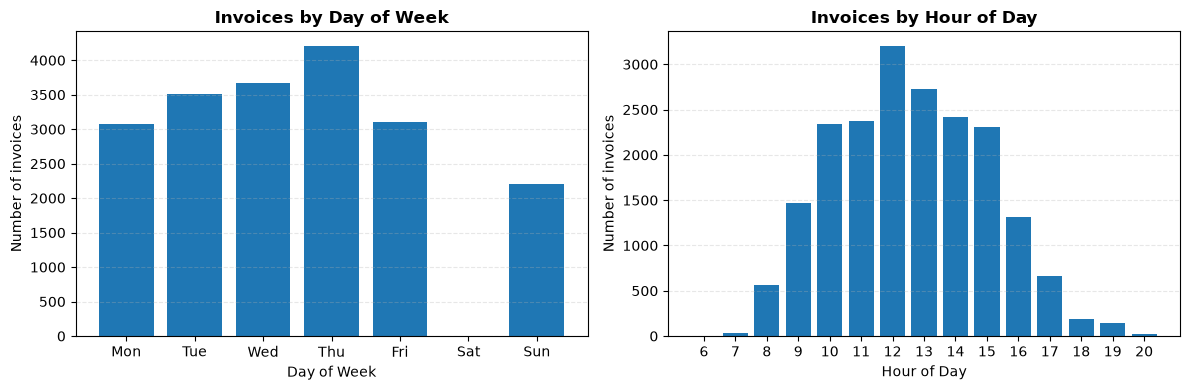

In [21]:
x_days = [d[:3] for d in weekday_order]
y_days = invoices_by_weekday.values

x_hours = invoices_by_hour.index
y_hours = invoices_by_hour.values

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left plot: Invoices by weekday
axes[0].bar(x_days, y_days, color="#1f77b4")
axes[0].set_title("Invoices by Day of Week", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Day of Week")
axes[0].set_ylabel("Number of invoices")
axes[0].grid(axis="y", linestyle="--", alpha=0.3)

# Right plot: Invoices by hour of day
axes[1].bar(x_hours, y_hours, color="#1f77b4")
axes[1].set_title("Invoices by Hour of Day", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Hour of Day")
axes[1].set_ylabel("Number of invoices")
axes[1].set_xticks(range(6, 21))
axes[1].grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
fig.savefig("../reports/shopping_times.png", dpi=150, bbox_inches="tight")
plt.show()

The busiest day is Thursday with 4,209 invoices (21.29% of all invoices and 2,131,558.05 in revenue). There are no invoices at all on Saturdays in this data, and Sunday is the quietest day with sales (2,203 invoices). By hour, the shop is busiest at 12:00 with 3,204 invoices, and about 77.8% of all invoices are made between 10:00 and 15:59. Only about 2% of the invoices are made before 8:00 or from 18:00 onwards. I don't know why there is no Saturday in the data, so I treat it as a gap and not as a conclusion about the customers.

## 6. Distribution of Recency, Frequency and Monetary

K-Means works with distances, so it is sensitive to the shape of the data. Here I look at how Recency, Frequency and Monetary are spread out, and I check whether a log transform makes them more balanced. This is my last look at the data before I build the segments.

In [22]:
rfm_quantile = round(rfm.quantile([0.01, 0.05, 0.5, 0.95, 0.99]), 2)
print(rfm_quantile)

pct_freq_1 = round((rfm["Frequency"] == 1).mean() * 100, 1)
pct_rec_le_30 = round((rfm["Recency"] <= 30).mean() * 100, 1)
pct_rec_gt_180 = round((rfm["Recency"] > 180).mean() * 100, 1)

print(f"\nCustomers with Frequency == 1: {pct_freq_1}%")
print(f"Customers with Recency <= 30: {pct_rec_le_30}%")
print(f"Customers with Recency > 180: {pct_rec_gt_180}%")

count_monetary_gt_5000 = (rfm["Monetary"] > 5000).sum()
print(f"Customers with Monetary > 5000: {count_monetary_gt_5000}")

      Recency  Frequency  Monetary
0.01      2.0        1.0     52.04
0.05      3.0        1.0    110.40
0.50     51.0        2.0    650.42
0.95    312.0       13.0   5657.14
0.99    369.0       30.0  17061.55

Customers with Frequency == 1: 34.6%
Customers with Recency <= 30: 37.6%
Customers with Recency > 180: 19.9%
Customers with Monetary > 5000: 260


In [23]:
rfm_log = np.log1p(rfm)
skew_table = pd.DataFrame({
    "raw": rfm.skew(),
    "log": rfm_log.skew()
}).round(2)

print("Skewness Comparison Table:")
print(skew_table)

assert rfm_log.shape == rfm.shape, "Shape mismatch between rfm_log and rfm"

assert np.isfinite(rfm_log).all().all(), "Non-finite values (NaN or Inf) found in rfm_log"

assert (rfm_log.skew().abs() < rfm.skew().abs()).all(), "Absolute skewness did not decrease for all columns"

Skewness Comparison Table:
             raw   log
Recency     1.24 -0.32
Frequency  11.94  1.21
Monetary   21.57  0.36


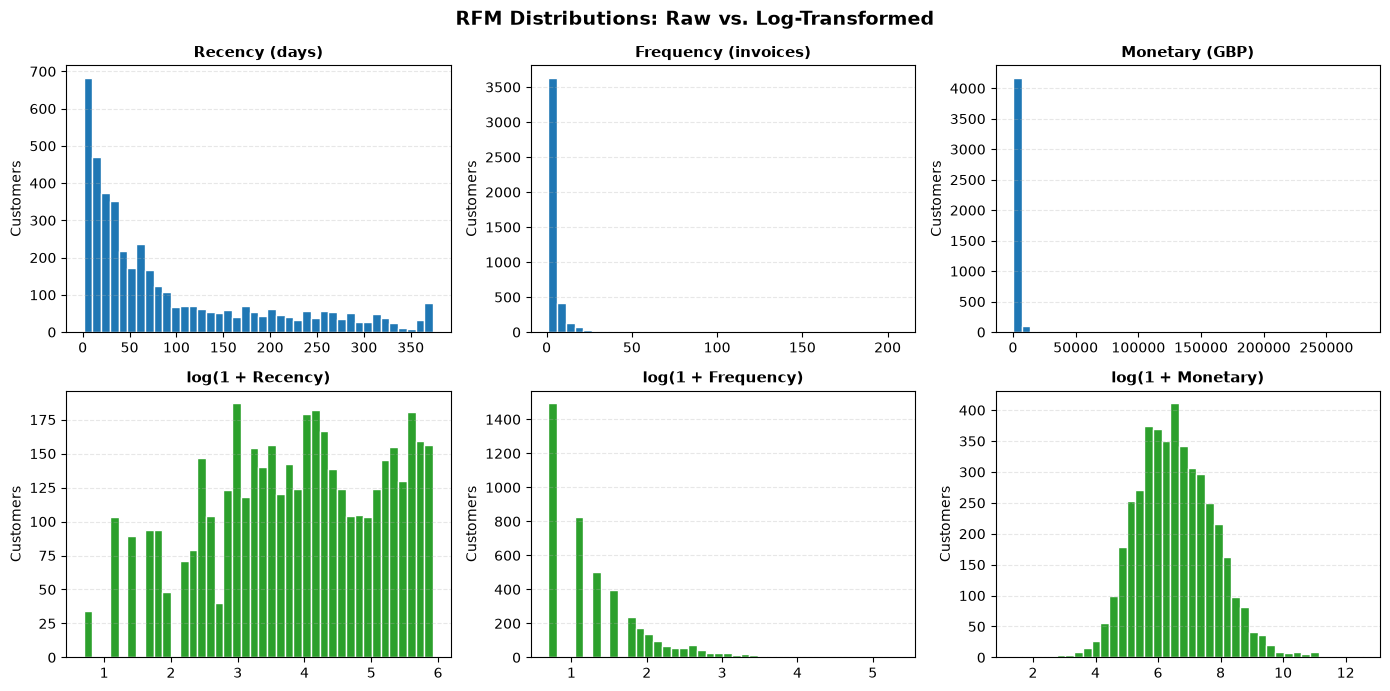

In [24]:
cols = ["Recency", "Frequency", "Monetary"]
raw_titles = ["Recency (days)", "Frequency (invoices)", "Monetary (GBP)"]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))

for i, col in enumerate(cols):

    axes[0, i].hist(rfm[col], bins=40, color="#1f77b4", edgecolor="white")
    axes[0, i].set_title(raw_titles[i], fontsize=11, fontweight="bold")
    axes[0, i].set_ylabel("Customers")
    axes[0, i].grid(axis="y", linestyle="--", alpha=0.3)

    axes[1, i].hist(rfm_log[col], bins=40, color="#2ca02c", edgecolor="white")
    axes[1, i].set_title(f"log(1 + {col})", fontsize=11, fontweight="bold")
    axes[1, i].set_ylabel("Customers")
    axes[1, i].grid(axis="y", linestyle="--", alpha=0.3)

fig.suptitle("RFM Distributions: Raw vs. Log-Transformed", fontsize=14, fontweight="bold")

plt.tight_layout()
fig.savefig("../reports/rfm_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

Recency is spread over the whole year: 37.6% of the customers bought in the last 30 days, and 19.9% have not bought for more than 180 days. Frequency is very uneven: 34.6% of the customers placed only one order, the median is 2 orders, the 99th percentile is 30 and the maximum is 206. Monetary has an even longer tail: the median customer spent 650.42, the 99th percentile is 17,061.55 and the maximum is 278,778.02. The skewness is 1.24 for Recency, 11.94 for Frequency and 21.57 for Monetary, and after log(1 + x) it drops to -0.32, 1.21 and 0.36. Because a few customers are so far from the rest, K-Means on the raw values would mostly separate those few from everybody else, so I will cluster on the log values, after scaling them.

## 7. Relationships and customer value

Now I check how Recency, Frequency and Monetary relate to each other, and how much of the total spending comes from the biggest customers. If two of the three numbers say almost the same thing, clustering on both of them counts that information twice.

In [25]:
rank_corr = rfm.corr(method="spearman").round(2)
print(rank_corr)

           Recency  Frequency  Monetary
Recency       1.00      -0.56     -0.49
Frequency    -0.56       1.00      0.81
Monetary     -0.49       0.81      1.00


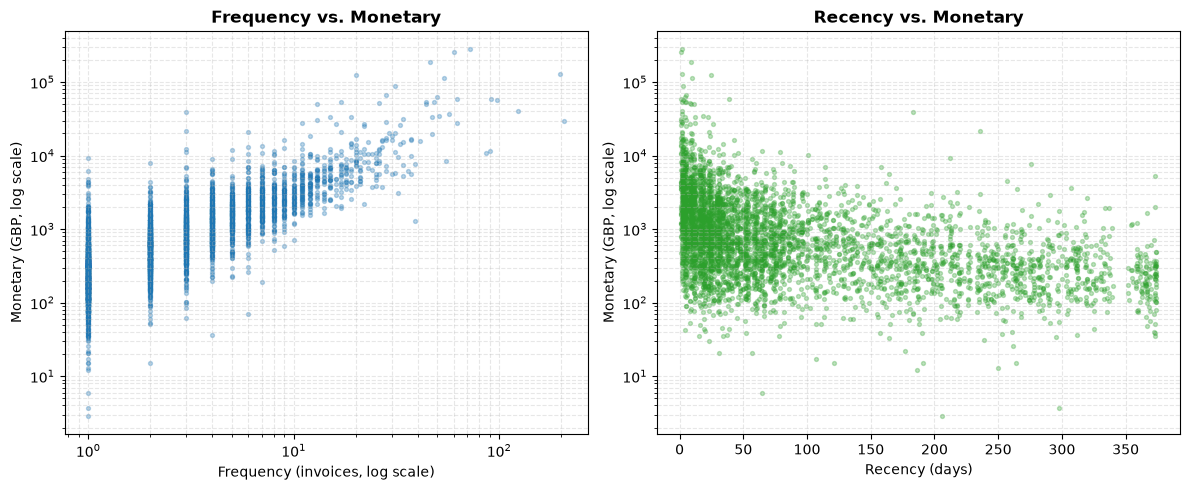

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Left plot: Frequency vs. Monetary (both axes on log scale)
axes[0].scatter(rfm["Frequency"], rfm["Monetary"], s=8, alpha=0.3, color="#1f77b4")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_title("Frequency vs. Monetary", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Frequency (invoices, log scale)")
axes[0].set_ylabel("Monetary (GBP, log scale)")
axes[0].grid(True, which="both", linestyle="--", alpha=0.3)

# Right plot: Recency vs. Monetary (y-axis on log scale)
axes[1].scatter(rfm["Recency"], rfm["Monetary"], s=8, alpha=0.3, color="#2ca02c")
axes[1].set_yscale("log")
axes[1].set_title("Recency vs. Monetary", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Recency (days)")
axes[1].set_ylabel("Monetary (GBP, log scale)")
axes[1].grid(True, which="both", linestyle="--", alpha=0.3)

# Adjust layout, save figure, and display
plt.tight_layout()
fig.savefig("../reports/rfm_relationships.png", dpi=150, bbox_inches="tight")
plt.show()

In [27]:
monetary_sorted = rfm["Monetary"].sort_values(ascending=False)
total_monetary = monetary_sorted.sum()
n_customers = len(rfm)

n_top_1 = int(n_customers * 0.01)
n_top_10 = int(n_customers * 0.10)
n_top_20 = int(n_customers * 0.20)
n_bottom_50 = int(n_customers * 0.50)

share_top_1 = round((monetary_sorted.head(n_top_1).sum() / total_monetary) * 100, 1)
share_top_10 = round((monetary_sorted.head(n_top_10).sum() / total_monetary) * 100, 1)
share_top_20 = round((monetary_sorted.head(n_top_20).sum() / total_monetary) * 100, 1)
share_bottom_50 = round((monetary_sorted.tail(n_bottom_50).sum() / total_monetary) * 100, 1)

print(f"Top 1% ({n_top_1} customers): {share_top_1}% of total revenue")
print(f"Top 10% ({n_top_10} customers): {share_top_10}% of total revenue")
print(f"Top 20% ({n_top_20} customers): {share_top_20}% of total revenue")
print(f"Bottom 50% ({n_bottom_50} customers): {share_bottom_50}% of total revenue")

Top 1% (43 customers): 30.1% of total revenue
Top 10% (432 customers): 60.1% of total revenue
Top 20% (864 customers): 73.7% of total revenue
Bottom 50% (2160 customers): 8.1% of total revenue


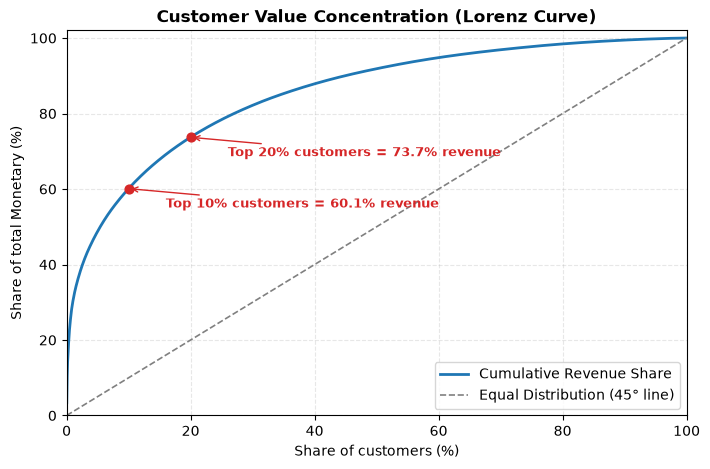

In [28]:
customer_cumulative = monetary_sorted.cumsum() / monetary_sorted.sum() * 100

x_customers = np.arange(1, len(rfm) + 1) / len(rfm) * 100

fig, ax = plt.subplots(figsize=(8, 5))

# 3. Plot Lorenz/Pareto cumulative curve and diagonal equality reference line
ax.plot(x_customers, customer_cumulative.values, color="#1f77b4", linewidth=2, label="Cumulative Revenue Share")
ax.plot([0, 100], [0, 100], color="gray", linestyle="--", linewidth=1.2, label="Equal Distribution (45° line)")

# 4. Highlight and annotate the Top 10% and Top 20% customer milestones
milestones = [
    (10, share_top_10),
    (20, share_top_20)
]

for pct_cust, pct_rev in milestones:
    ax.scatter(pct_cust, pct_rev, color="#d62728", zorder=5, s=40)
    ax.annotate(
        f"Top {pct_cust}% customers = {pct_rev}% revenue",
        xy=(pct_cust, pct_rev),
        xytext=(pct_cust + 6, pct_rev - 5),
        fontsize=9,
        fontweight="bold",
        color="#d62728",
        arrowprops=dict(arrowstyle="->", color="#d62728", lw=1)
    )

# 5. Set title, axis labels, limits, grid, and legend
ax.set_title("Customer Value Concentration (Lorenz Curve)", fontsize=12, fontweight="bold")
ax.set_xlabel("Share of customers (%)")
ax.set_ylabel("Share of total Monetary (%)")
ax.set_xlim(0, 100)
ax.set_ylim(0, 102)
ax.grid(True, linestyle="--", alpha=0.3)
ax.legend(loc="lower right")

# Save figure before plt.show()
fig.savefig("../reports/customer_value_concentration.png", dpi=150, bbox_inches="tight")
plt.show()

Frequency and Monetary move together (Spearman correlation 0.81): customers who order more often also spend more. Recency has a negative correlation with both Frequency (-0.56) and Monetary (-0.49), because customers who bought recently tend to be the active ones. Frequency and Monetary are strongly related but not identical, so I keep all three in the clustering. The value is also very concentrated: the top 1% of the customers (43 customers) bring in 30.1% of the Monetary value, the top 10% bring in 60.1% and the top 20% bring in 73.7%, while the bottom half brings in only 8.1%. Most of the value comes from a small group of frequent buyers, which is exactly what the segmentation should find.

## 8. Summary

What the exploration showed:

| Topic | Finding |
|---|---|
| Sales over time | Revenue peaks in November 2011 (1.45 million). December 2011 only looks low because the data stops on 9 December, and per active day it is almost the same as November |
| Countries | The UK brings in 84.77% of the revenue. The top five other countries (Netherlands, EIRE, Germany, France, Australia) make up about 71% of the non-UK revenue |
| Products | No product dominates: the top 10 bring in 8.22% of the revenue, and 832 products (22.0%) make up 80% of it |
| Shopping times | Thursday is the busiest day, there are no invoices on Saturday, and about 78% of the invoices are made between 10:00 and 15:59 |
| RFM distributions | Strongly skewed to the right (skewness 1.24, 11.94 and 21.57). After log(1 + x) it is -0.32, 1.21 and 0.36 |
| Relationships | Frequency and Monetary are strongly related (Spearman 0.81), and Recency has a negative relation with both |
| Customer value | The top 10% of the customers bring in 60.1% of the Monetary value, and the bottom half only 8.1% |

What this means for the segmentation:

- I cluster on log(1 + x) of Recency, Frequency and Monetary, after scaling them.
- Most of the revenue is from the UK, so I will not cluster each country separately, but I will check the segments by country afterwards.
- The reference date for Recency is 2011-12-10, and December 2011 is a partial month.
- All the charts are saved in `reports/`.

Next is `05_segmentation.ipynb`, where I cluster the customers with K-Means and describe each segment.